<a href="https://colab.research.google.com/github/takiet485-coder/animals-classifier/blob/main/DuDoanDongVatQuyHiem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Tải dataset Animals-10
!kaggle datasets download -d alessiocorrado99/animals10
!unzip -q animals10.zip -d animals10

print("✅ Dataset đã sẵn sàng!")
!ls animals10/raw-img

Dataset URL: https://www.kaggle.com/datasets/alessiocorrado99/animals10
License(s): GPL-2.0
100% 586M/586M [00:25<00:00, 23.6MB/s]

✅ Dataset đã sẵn sàng!
cane	 elefante  gallina  mucca   ragno
cavallo  farfalla  gatto    pecora  scoiattolo


In [3]:
import os
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

# Animals-10 dùng tên tiếng Ý, mình map sang tiếng Anh + tên khoa học
CLASS_MAP = {
    "cane":        {"en": "dog",       "scientific": "Canis lupus familiaris"},
    "cavallo":     {"en": "horse",     "scientific": "Equus caballus"},
    "elefante":    {"en": "elephant",  "scientific": "Loxodonta africana"},
    "farfalla":    {"en": "butterfly", "scientific": "Rhopalocera"},
    "gallina":     {"en": "chicken",   "scientific": "Gallus gallus"},
    "gatto":       {"en": "cat",       "scientific": "Felis catus"},
    "mucca":       {"en": "cow",       "scientific": "Bos taurus"},
    "pecora":      {"en": "sheep",     "scientific": "Ovis aries"},
    "ragno":       {"en": "spider",    "scientific": "Araneae"},
    "scoiattolo":  {"en": "squirrel",  "scientific": "Sciurus vulgaris"},
}

SOURCE = "animals10/raw-img"
TRAIN_DIR = "data_animals10/train"
VAL_DIR   = "data_animals10/val"
TEST_DIR  = "data_animals10/test"

for d in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    if os.path.exists(d):
        shutil.rmtree(d)
    os.makedirs(d)

random.seed(42)
CLASSES = list(CLASS_MAP.keys())

# GIỚI HẠN SỐ ẢNH MỖI LOÀI (Ví dụ: 30 ảnh/loài * 10 loài = 300 ảnh tổng cộng)
MAX_IMAGES_PER_CLASS = 30

print("Đang chia dữ liệu (bản rút gọn nhanh)...")
for cls in CLASSES:
    src = os.path.join(SOURCE, cls)
    images = [f for f in os.listdir(src) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    random.shuffle(images)

    # Cắt giảm số lượng ảnh tối đa cho mỗi loài trước khi chia
    images = images[:MAX_IMAGES_PER_CLASS]
    n = len(images)

    n_train = int(0.70 * n)
    n_val   = int(0.15 * n)

    for folder, img_list in [
        (TRAIN_DIR, images[:n_train]),
        (VAL_DIR,   images[n_train:n_train+n_val]),
        (TEST_DIR,  images[n_train+n_val:])
    ]:
        dest = os.path.join(folder, CLASS_MAP[cls]["en"])
        os.makedirs(dest, exist_ok=True)
        for img in img_list:
            shutil.copy(os.path.join(src, img), os.path.join(dest, img))

    print(f"  {CLASS_MAP[cls]['en']:10s} → Train: {n_train:4d} | Val: {n_val:3d} | Test: {n-n_train-n_val:3d}")

TensorFlow: 2.21.0
GPU: []
Đang chia dữ liệu (bản rút gọn nhanh)...
  dog        → Train:   21 | Val:   4 | Test:   5
  horse      → Train:   21 | Val:   4 | Test:   5
  elephant   → Train:   21 | Val:   4 | Test:   5
  butterfly  → Train:   21 | Val:   4 | Test:   5
  chicken    → Train:   21 | Val:   4 | Test:   5
  cat        → Train:   21 | Val:   4 | Test:   5
  cow        → Train:   21 | Val:   4 | Test:   5
  sheep      → Train:   21 | Val:   4 | Test:   5
  spider     → Train:   21 | Val:   4 | Test:   5
  squirrel   → Train:   21 | Val:   4 | Test:   5


In [4]:
IMG_SIZE = 224
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE, class_mode='categorical', shuffle=True
)

val_gen = val_test_datagen.flow_from_directory(
    VAL_DIR, target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False
)

test_gen = val_test_datagen.flow_from_directory(
    TEST_DIR, target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False
)

print("Class indices:", train_gen.class_indices)

Found 210 images belonging to 10 classes.
Found 40 images belonging to 10 classes.
Found 50 images belonging to 10 classes.
Class indices: {'butterfly': 0, 'cat': 1, 'chicken': 2, 'cow': 3, 'dog': 4, 'elephant': 5, 'horse': 6, 'sheep': 7, 'spider': 8, 'squirrel': 9}


In [5]:
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dropout(0.4)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(len(train_gen.class_indices), activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=outputs)

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,428,362 (9.26 MB)

 Trainable params: 167,818 (655.54 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [6]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3, min_lr=1e-7, verbose=1),
    ModelCheckpoint('best_animals10_model.h5', monitor='val_accuracy', save_best_only=True, verbose=1)
]

In [7]:
print("========== PHASE 1: Feature Extraction ==========")
history1 = model.fit(
    train_gen,
    epochs=12,
    validation_data=val_gen,
    callbacks=callbacks
)

========== PHASE 1: Feature Extraction ==========
Epoch 1/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.1260 - loss: 3.2859
Epoch 1: val_accuracy improved from None to 0.50000, saving model to best_animals10_model.h5



Epoch 1: finished saving model to best_animals10_model.h5
7/7 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.1667 - loss: 3.0170 - val_accuracy: 0.5000 - val_loss: 1.5884 - learning_rate: 0.0010
Epoch 2/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4504 - loss: 1.7491
Epoch 2: val_accuracy improved from 0.50000 to 0.70000, saving model to best_animals10_model.h5



Epoch 2: finished saving model to best_animals10_model.h5
7/7 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.5381 - loss: 1.5044 - val_accuracy: 0.7000 - val_loss: 1.0191 - learning_rate: 0.0010
Epoch 3/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6701 - loss: 0.9561
Epoch 3: val_accuracy improved from 0.70000 to 0.80000, saving model to best_animals10_model.h5



Epoch 3: finished saving model to best_animals10_model.h5
7/7 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.7143 - loss: 0.8238 - val_accuracy: 0.8000 - val_loss: 0.7484 - learning_rate: 0.0010
Epoch 4/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7906 - loss: 0.6064
Epoch 4: val_accuracy improved from 0.80000 to 0.85000, saving model to best_animals10_model.h5



Epoch 4: finished saving model to best_animals10_model.h5
7/7 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.8095 - loss: 0.5089 - val_accuracy: 0.8500 - val_loss: 0.5824 - learning_rate: 0.0010
Epoch 5/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8457 - loss: 0.4228
Epoch 5: val_accuracy did not improve from 0.85000
7/7 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.8571 - loss: 0.3851 - val_accuracy: 0.8500 - val_loss: 0.4788 - learning_rate: 0.0010
Epoch 6/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8440 - loss: 0.3939
Epoch 6: val_accuracy improved from 0.85000 to 0.87500, saving model to best_animals10_model.h5



Epoch 6: finished saving model to best_animals10_model.h5
7/7 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.8524 - loss: 0.3755 - val_accuracy: 0.8750 - val_loss: 0.4079 - learning_rate: 0.0010
Epoch 7/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8899 - loss: 0.2731
Epoch 7: val_accuracy did not improve from 0.87500
7/7 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.8905 - loss: 0.2827 - val_accuracy: 0.8750 - val_loss: 0.3739 - learning_rate: 0.0010
Epoch 8/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9308 - loss: 0.2047
Epoch 8: val_accuracy improved from 0.87500 to 0.90000, saving model to best_animals10_model.h5



Epoch 8: finished saving model to best_animals10_model.h5
7/7 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.9190 - loss: 0.2308 - val_accuracy: 0.9000 - val_loss: 0.3526 - learning_rate: 0.0010
Epoch 9/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9681 - loss: 0.1534
Epoch 9: val_accuracy did not improve from 0.90000
7/7 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.9476 - loss: 0.1765 - val_accuracy: 0.9000 - val_loss: 0.3331 - learning_rate: 0.0010
Epoch 10/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9021 - loss: 0.3047
Epoch 10: val_accuracy improved from 0.90000 to 0.92500, saving model to best_animals10_model.h5



Epoch 10: finished saving model to best_animals10_model.h5
7/7 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.9143 - loss: 0.2718 - val_accuracy: 0.9250 - val_loss: 0.3094 - learning_rate: 0.0010
Epoch 11/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9538 - loss: 0.1731
Epoch 11: val_accuracy improved from 0.92500 to 0.95000, saving model to best_animals10_model.h5



Epoch 11: finished saving model to best_animals10_model.h5
7/7 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.9571 - loss: 0.1812 - val_accuracy: 0.9500 - val_loss: 0.2837 - learning_rate: 0.0010
Epoch 12/12
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9666 - loss: 0.1465
Epoch 12: val_accuracy did not improve from 0.95000
7/7 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.9571 - loss: 0.1621 - val_accuracy: 0.9500 - val_loss: 0.2699 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 12.


In [ ]:
print("========== PHASE 2: Fine-tuning ==========")

# 1. Mở khóa base_model để tinh chỉnh sâu hơn
base_model.trainable = True

# Vì dataset nhỏ (~300 ảnh), ta nên khóa bớt nhiều lớp đầu hơn (ví dụ 120 lớp)
# để tránh làm hỏng các đặc trưng tổng quát đã học từ ảnh gốc.
for layer in base_model.layers[:120]:
    layer.trainable = False

# 2. Biên dịch lại model với learning rate CỰC KỲ NHỎ (1e-5)
model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Giảm số epochs xuống (từ 15 xuống 5 hoặc 8) vì dataset ít, train rất nhanh
history2 = model.fit(
    train_gen,
    epochs=8,               # Giảm số vòng lặp để phù hợp với dataset nhỏ
    validation_data=val_gen,
    callbacks=callbacks     # EarlyStopping sẽ tự động dừng nếu mô hình đã đạt tối ưu
)

print("🎉 Hoàn thành huấn luyện Giai đoạn 2!")

========== PHASE 2: Fine-tuning ==========
Epoch 1/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8085 - loss: 0.5145
Epoch 1: val_accuracy did not improve from 0.90000
7/7 ━━━━━━━━━━━━━━━━━━━━ 35s 3s/step - accuracy: 0.8286 - loss: 0.4611 - val_accuracy: 0.9000 - val_loss: 0.3311 - learning_rate: 1.0000e-05
Epoch 2/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8682 - loss: 0.3281
Epoch 2: val_accuracy did not improve from 0.90000
7/7 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - accuracy: 0.9000 - loss: 0.2895 - val_accuracy: 0.9000 - val_loss: 0.3263 - learning_rate: 1.0000e-05
Epoch 3/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8976 - loss: 0.2685
Epoch 3: val_accuracy did not improve from 0.90000
7/7 ━━━━━━━━━━━━━━━━━━━━ 21s 3s/step - accuracy: 0.9000 - loss: 0.3003 - val_accuracy: 0.9000 - val_loss: 0.3177 - learning_rate: 1.0000e-05
Epoch 4/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8973 - loss: 0.2835
Epoch 4: val_accuracy did not improve from 0.90000
7/7 ━━━━━━

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 864ms/step - accuracy: 0.9200 - loss: 0.3361

✅ Test Accuracy: 92.00%
2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step

Classification Report:
              precision    recall  f1-score   support

   butterfly       1.00      1.00      1.00         5
         cat       1.00      1.00      1.00         5
     chicken       0.83      1.00      0.91         5
         cow       0.71      1.00      0.83         5
         dog       1.00      0.60      0.75         5
    elephant       0.83      1.00      0.91         5
       horse       1.00      0.60      0.75         5
       sheep       1.00      1.00      1.00         5
      spider       1.00      1.00      1.00         5
    squirrel       1.00      1.00      1.00         5

    accuracy                           0.92        50
   macro avg       0.94      0.92      0.92        50
weighted avg       0.94      0.92      0.92        50



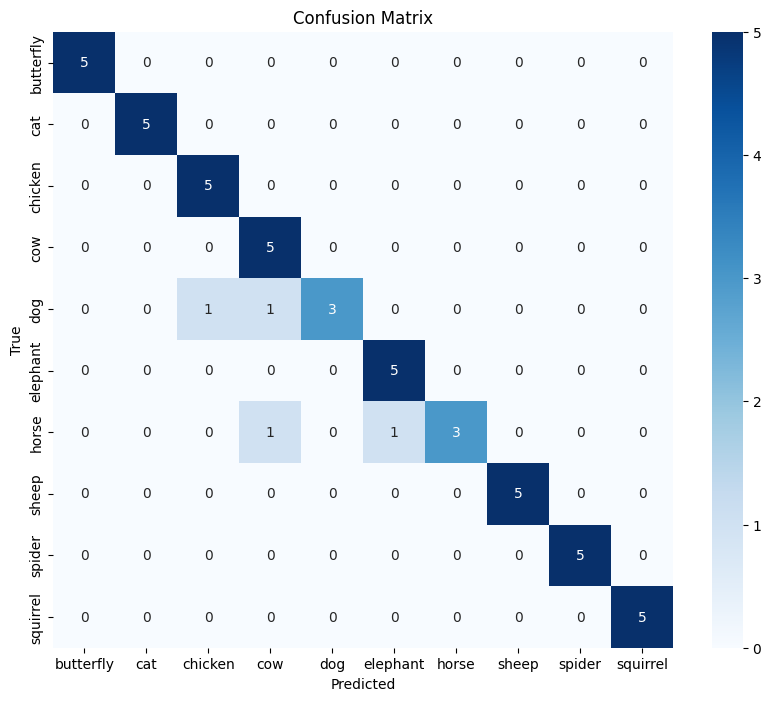

✅ Đã lưu model: animals10_classifier.h5


In [ ]:
test_loss, test_acc = model.evaluate(test_gen)
print(f"\n✅ Test Accuracy: {test_acc*100:.2f}%")

y_pred = model.predict(test_gen)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_gen.classes

print("\nClassification Report:")
print(classification_report(y_true, y_pred_classes, target_names=list(train_gen.class_indices.keys())))

cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=train_gen.class_indices.keys(),
            yticklabels=train_gen.class_indices.keys())
plt.title('Confusion Matrix')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.show()

model.save("animals10_classifier.h5")
print("✅ Đã lưu model: animals10_classifier.h5")

In [ ]:
from tensorflow.keras.optimizers import Adam

print("========== PHASE 2: Fine-Tuning ==========")

# 1. Mở đóng băng base_model
base_model.trainable = True

for layer in base_model.layers[:120]:
    layer.trainable = False

# 2. Compile lại model với learning rate CỰC KỲ NHỎ (1e-5)
model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("🔄 Đã mở khóa mô hình (Fine-Tuning). Đang huấn luyện thêm...")

# 3. Tiếp tục train (Fine-tuning) khoảng 5-8 epochs (vì dataset ít nên sẽ hội tụ rất nhanh)
EPOCHS_FINE = 8
history_fine = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_FINE,
    callbacks=callbacks      # EarlyStopping sẽ tự động dừng sớm nếu mô hình đã tối ưu
)

print("🎉 Hoàn thành Giai đoạn 2: Fine-Tuning!")

========== PHASE 2: Fine-Tuning ==========
🔄 Đã mở khóa mô hình (Fine-Tuning). Đang huấn luyện thêm...
Epoch 1/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9171 - loss: 0.2549
Epoch 1: val_accuracy did not improve from 0.90000
7/7 ━━━━━━━━━━━━━━━━━━━━ 35s 3s/step - accuracy: 0.9190 - loss: 0.2408 - val_accuracy: 0.9000 - val_loss: 0.2915 - learning_rate: 1.0000e-05
Epoch 2/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9530 - loss: 0.1796
Epoch 2: val_accuracy did not improve from 0.90000
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.9381 - loss: 0.1949 - val_accuracy: 0.9000 - val_loss: 0.2894 - learning_rate: 1.0000e-05
Epoch 3/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9367 - loss: 0.2719
Epoch 3: val_accuracy did not improve from 0.90000
7/7 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - accuracy: 0.9238 - loss: 0.2976 - val_accuracy: 0.9000 - val_loss: 0.2895 - learning_rate: 1.0000e-05
Epoch 4/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9175 - loss: 0.2622
E

📊 Đang đánh giá mô hình trên tập Test...
2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.9200 - loss: 0.3224

✅ Test Accuracy (Độ chính xác): 92.00%
2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step

📋 Classification Report:
              precision    recall  f1-score   support

   butterfly       1.00      1.00      1.00         5
         cat       1.00      1.00      1.00         5
     chicken       0.83      1.00      0.91         5
         cow       0.71      1.00      0.83         5
         dog       1.00      0.60      0.75         5
    elephant       0.83      1.00      0.91         5
       horse       1.00      0.60      0.75         5
       sheep       1.00      1.00      1.00         5
      spider       1.00      1.00      1.00         5
    squirrel       1.00      1.00      1.00         5

    accuracy                           0.92        50
   macro avg       0.94      0.92      0.92        50
weighted avg       0.94      0.92      0.92        50



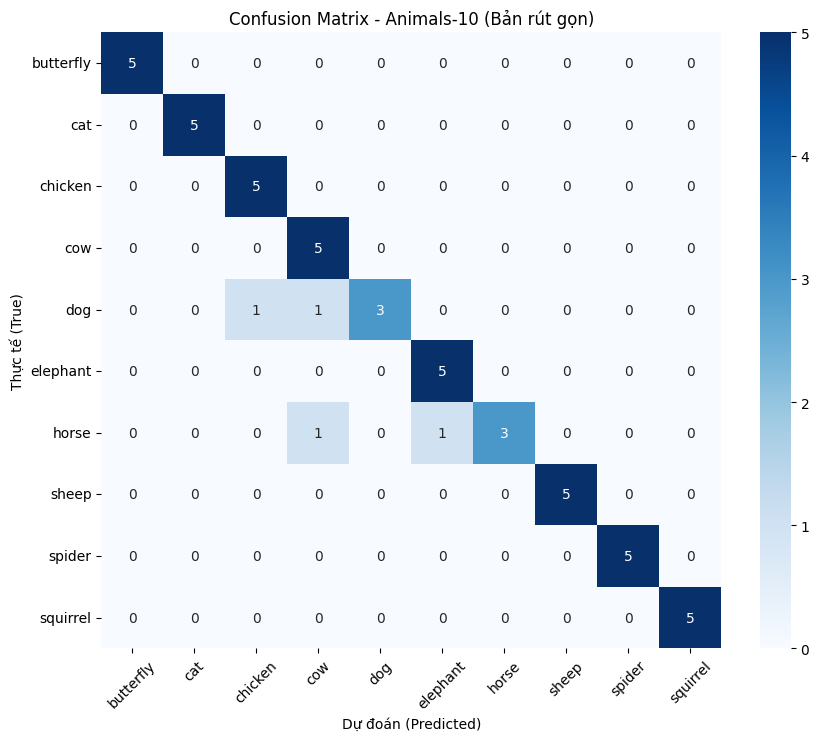

🎉 Đã lưu model thành công vào file: animals10_classifier.h5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 1. Đánh giá mô hình trên tập Test
print("📊 Đang đánh giá mô hình trên tập Test...")
test_loss, test_acc = model.evaluate(test_gen)
print(f"\n✅ Test Accuracy (Độ chính xác): {test_acc*100:.2f}%")

# 2. Dự đoán và tạo báo cáo chi tiết
y_pred = model.predict(test_gen)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_gen.classes

class_names = list(train_gen.class_indices.keys())

print("\n📋 Classification Report:")
print(classification_report(y_true, y_pred_classes, target_names=class_names))

# 3. Vẽ biểu đồ Confusion Matrix (Ma trận nhầm lẫn)
cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Confusion Matrix - Animals-10 (Bản rút gọn)')
plt.ylabel('Thực tế (True)')
plt.xlabel('Dự đoán (Predicted)')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

# 4. Lưu lại mô hình hoàn chỉnh để dùng về sau
model.save("animals10_classifier.h5")
print("🎉 Đã lưu model thành công vào file: animals10_classifier.h5")

# (Tùy chọn) Tải file model về máy tính cá nhân để cất giữ
from google.colab import files
files.download("animals10_classifier.h5")

In [1]:
from google.colab import files
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import numpy as np

# 1. Cơ sở dữ liệu sinh học chi tiết cho từng loài
BIO_DATABASE = {
    "dog": {
        "vn_name": "Chó nhà",
        "scientific": "Canis lupus familiaris",
        "iucn": "Ít quan tâm (Least Concern - LC)",
        "habitat": "Sống gần con người, thích nghi rộng rãi với mọi môi trường từ nông thôn đến đô thị.",
        "behavior": "Sống bầy đàn, trung thành, thông minh và có tính xã hội cao.",
        "lifespan": "10 - 13 năm"
    },
    "horse": {
        "vn_name": "Ngựa",
        "scientific": "Equus caballus",
        "iucn": "Thuần hóa / Gần bị đe dọa trong tự nhiên",
        "habitat": "Đồng cỏ rộng lớn, thảo nguyên hoặc được nuôi trong các trang trại.",
        "behavior": "Động vật ăn cỏ, sống theo bầy đàn, chạy rất nhanh và có phản xạ cảnh giác cao.",
        "lifespan": "25 - 30 năm"
    },
    "elephant": {
        "vn_name": "Voi châu Phi / Voi châu Á",
        "scientific": "Loxodonta africana",
        "iucn": "Đang nguy cấp / Cần bảo vệ nghiêm ngặt (Endangered / Vulnerable)",
        "habitat": "Rừng nhiệt đới, thảo nguyên và vùng đất cây bụi châu Phi/châu Á.",
        "behavior": "Sống theo mẫu hệ, có trí nhớ siêu phàm, giao tiếp bằng âm thanh tần số thấp.",
        "lifespan": "60 - 70 năm"
    },
    "butterfly": {
        "vn_name": "Bướm",
        "scientific": "Rhopalocera",
        "iucn": "Đa số Ít quan tâm (Nhiều loài đang suy giảm do mất môi trường sống)",
        "habitat": "Khu vực có nhiều hoa, vườn cây, rừng nhiệt đới và ôn đới.",
        "behavior": "Thụ phấn cho hoa, hoạt động ban ngày, trải qua quá trình biến thái (trứng -> sâu -> nhộng -> bướm).",
        "lifespan": "Vài tuần đến vài tháng (tùy loài)"
    },
    "chicken": {
        "vn_name": "Gà nhà",
        "scientific": "Gallus gallus domesticus",
        "iucn": "Loài nuôi / Ít quan tâm",
        "habitat": "Trang trại, chuồng trại nông nghiệp do con người quản lý.",
        "behavior": "Ăn tạp (hạt, côn trùng), có hệ thống phân cấp thứ bậc (mổ tranh quyền lực), bay kém.",
        "lifespan": "5 - 10 năm"
    },
    "cat": {
        "vn_name": "Mèo nhà",
        "scientific": "Felis catus",
        "iucn": "Ít quan tâm (Least Concern)",
        "habitat": "Sống trong các hộ gia đình hoặc hoang dã đô thị.",
        "behavior": "Động vật ăn thịt đơn độc, thính giác và thị giác tinh nhạy, thích leo trèo và ngủ nhiều.",
        "lifespan": "12 - 15 năm (có thể hơn)"
    },
    "cow": {
        "vn_name": "Bò nhà",
        "scientific": "Bos taurus",
        "iucn": "Được thuần hóa / Ít quan tâm",
        "habitat": "Đồng cỏ, nông trại chăn nuôi.",
        "behavior": "Động vật ăn cỏ nhai lại, sống hiền lành theo đàn.",
        "lifespan": "15 - 20 năm"
    },
    "sheep": {
        "vn_name": "Cừu",
        "scientific": "Ovis aries",
        "iucn": "Được thuần hóa / Ít quan tâm",
        "habitat": "Vùng đồi núi, thảo nguyên, đồng cỏ nhân tạo.",
        "behavior": "Tính bầy đàn cực kỳ cao, phản xạ đi theo con đầu đàn rõ rệt.",
        "lifespan": "10 - 12 năm"
    },
    "spider": {
        "vn_name": "Nhện",
        "scientific": "Araneae",
        "iucn": "Đa số Ít quan tâm (Một số loài quý hiếm cần bảo vệ)",
        "habitat": "Khắp mọi nơi trên Trái Đất (trừ Nam Cực), từ góc nhà, hang động đến rừng rậm.",
        "behavior": "Ăn thịt côn trùng, giăng tơ để bắt mồi, có loài độc tố cao.",
        "lifespan": "1 - 2 năm (có loài nhện cảnh sống tới 15-20 năm)"
    },
    "squirrel": {
        "vn_name": "Sóc",
        "scientific": "Sciurus vulgaris",
        "iucn": "Ít quan tâm (Least Concern)",
        "habitat": "Rừng cây ôn đới và nhiệt đới, công viên thành phố có nhiều cây lớn.",
        "behavior": "Leo trèo giỏi, nhanh nhẹn, có thói quen tích trữ hạt dẻ cho mùa đông.",
        "lifespan": "3 - 7 năm trong tự nhiên"
    }
}

# 2. Tải ảnh từ máy tính để test
print("📤 Vui lòng chọn một bức ảnh động vật từ máy tính của bạn:")
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# 3. Xử lý ảnh và dự đoán bằng model đã train
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

pred = model.predict(img_array)[0]
class_names = list(train_gen.class_indices.keys())
idx = np.argmax(pred)

species_en = class_names[idx]
confidence = pred[idx] * 100

# Lấy thông tin sinh học từ từ điển
info = BIO_DATABASE.get(species_en, {
    "vn_name": "Chưa có thông tin", "scientific": "Unknown",
    "iucn": "Đang cập nhật", "habitat": "Đang cập nhật",
    "behavior": "Đang cập nhật", "lifespan": "Đang cập nhật"
})

# 4. In kết quả chi tiết ra màn hình
print("\n" + "=" * 60)
print(f"🔍 KẾT QUẢ NHẬN DIỆN VÀ TRA CỨU SINH HỌC")
print("=" * 60)
print(f"🏷️  Tên tiếng Anh   : {species_en.upper()} ({info['vn_name']})")
print(f"🧬 Tên khoa học   : {info['scientific']}")
print(f"📊 Độ tin cậy     : {confidence:.1f}%")
print("-" * 60)
print(f"🛡️  Tình trạng IUCN : {info['iucn']}")
print(f"🏡 Môi trường sống: {info['habitat']}")
print(f"🐾 Tập tính       : {info['behavior']}")
print(f"⏳ Tuổi thọ       : {info['lifespan']}")
print("=" * 60)

# 5. Hiển thị ảnh kèm tiêu đề kết quả
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.title(f"Dự đoán: {species_en.upper()} ({confidence:.1f}%)", fontsize=12, color='darkgreen')
plt.axis('off')
plt.show()

📤 Vui lòng chọn một bức ảnh động vật từ máy tính của bạn:


Saving images (3).jpg to images (3).jpg


NameError: name 'model' is not defined